# 0. このNotebookの目的

このNotebookでは、電子製品を販売するEC企業の配送データを用いて、**データ分析に基づく事業提案の流れ**を体験します。

本Notebookの目的は、単に機械学習モデルを作ることではありません。市場分析・ドメイン分析によって「何を問題として扱うべきか」を考え、EDAによってその問題がデータ上でも確認できるかを見ます。そのうえで、課題仮説を立て、特徴量を作成し、モデルを用いて改善優先度の高い注文群・商品属性群を抽出し、最終的に事業提案として説明できる形に整理します。

今回の大きな問いは次の通りです。

> **配送遅延を減らすために、どの注文群・商品属性群の需給を優先的に確認すべきか？**

注意：このデータには実際の商品IDや在庫数は含まれていません。そのため、本Notebookでいう「製品群」は、実商品単位の厳密なグループではなく、価格・重量・重要度・在庫補填頻度・出荷頻度などから見た**分析上の注文群・商品属性群**を指します。

ただし、この問いは最初から決め打ちするものではありません。以下の分析の流れから導きます。

1. **市場分析**：EC市場の拡大や物流負荷の増加により、配送遅延が事業課題になりうることを確認する
2. **業務フロー整理**：配送遅延は、在庫補填・出荷・配送の流れの中で起きるため、需給バランスの問題として考えられることを整理する
3. **EDA**：今回のデータでも配送遅延が発生しているか、また割引率・重量・配送手段・倉庫・在庫補填頻度・出荷頻度と関係しそうかを確認する
4. **モデル化**：配送遅延リスクを予測し、どの注文群・商品属性群を優先的に見るべきかを考える

つまり本Notebookでは、**市場分析から課題候補を出し、EDAでデータ上の根拠を確認し、モデルで優先順位づけする**ことを目指します。

# 0-1. 最終課題で求められること

最終課題では、データを分析するだけでなく、企業に対する事業提案まで行うことが求められます。

重要なのは、以下の流れがつながっていることです。

1. 市場分析・ドメイン分析により、企業や業界の課題を理解する
2. EDAにより、今回のデータ上でどのような課題が見えるかを確認する
3. 課題仮説を立てる
4. 課題仮説を検証するために、追加のEDAや特徴量作成を行う
5. モデルを構築し、評価指標・スコアを確認する
6. モデルやEDAの結果から、定量的な示唆を得る
7. 打ち手を考え、どの対象から取り組むべきかを検討する

したがって、**「グラフを作った」「モデルを作った」だけでは不十分**です。分析結果から、企業がどのような意思決定をできるようになるのかを説明する必要があります。

特に重要なのは、以下です。

- **市場分析・ドメイン分析**：外部情報を使い、なぜその課題を扱うのかを説明すること
- **可視化**：枚数を増やすこと自体ではなく、主張が伝わる図表を目的意識をもって作ること
- **企業固有の課題設定**：一般論ではなく、今回のデータから企業固有の課題を示すこと
- **モデル構築・評価**：モデル名、評価指標、スコアを明記すること
- **定量的な示唆**：モデルやEDAの結果から、改善対象や優先順位を数字で説明すること
- **事業提案への接続**：分析結果を、具体的な施策候補や優先対象の整理につなげること

なお、この初心者版Notebookでは、施策実施後の効果を厳密にシミュレーションするところまでは扱いません。ここでは、**施策対象候補を抽出すること**を主な到達点とします。

# 0-2. データ分析に基づく事業提案の流れ

このNotebookでは、以下の流れで分析を進めます。

1. **市場分析・ドメイン分析**
   - EC市場や物流課題を調べ、配送遅延を問題として扱う理由を確認する

2. **データ理解・初期EDA**
   - データの構造、欠損値、カラムの意味、目的変数候補を確認する

3. **課題仮説立案**
   - 配送遅延が多いのではないか
   - 配送遅延が顧客評価に関係しているのではないか
   - 需給バランスが悪い注文群・商品属性群で遅延が起きているのではないか

4. **課題仮説の深掘り**
   - 割引率、重量、在庫補填頻度、出荷頻度などを確認する

5. **特徴量作成**
   - 在庫補填頻度と出荷頻度から、需給指標を作成する

6. **モデル構築・評価**
   - 配送遅延の有無を目的変数としてモデルを作成する

7. **優先対象の抽出**
   - 需給指標やモデルの予測結果を使って、改善対象候補を整理する

8. **事業提案としての整理**
   - どの注文群・商品属性群から確認すべきかを考える

# 0-3. issueドリブンなデータ分析

データ分析は、データを上から順に眺める作業ではありません。まず、**この企業にとって何を問題として扱うべきか**を考えます。そのうえで、その問題が本当にデータ上でも確認できるのか、どの変数で確認できるのか、どの打ち手につながるのかを見ていきます。

今回のEC配送データで最初に考えるべき問いは、

> このデータで何が予測できるか？

ではありません。より重要なのは、

> このEC企業にとって、どの業務課題を改善することにビジネス上の意味があるか？

です。

配送遅延を問題にするなら、配送遅延が多いこと、顧客評価と関係しそうなこと、需給バランスや在庫・出荷の意思決定に結びつくことを示す必要があります。

このNotebookでは、以下の流れを意識します。

市場・業務背景から問題候補を出す  
↓  
データでその問題がありそうか確認する  
↓  
問題を解くと誰の意思決定が変わるか考える  
↓  
仮説に基づいてさらに分析する  
↓  
モデルや特徴量で施策の優先順位をつける  
↓  
ビジネス効果として提案する

# 1.背景整理・EDA

このデータセットは2021年頃の、電子製品を販売している企業の電子商取引配送についてのデータである、という前提情報が与えられています。

そこで最初に、EC業界の市場規模、物流負荷、配送遅延が事業上なぜ重要なのかを整理します。

このNotebookでは、いきなりデータから課題を決めるのではなく、**市場分析・ドメイン分析から課題候補を出し、その課題が今回のデータでも確認できるかをEDAで検証する**、という流れで進めます。

## 市場分析・ドメイン分析の目的

市場分析・ドメイン分析は、外部情報をたくさん集めることが目的ではありません。

目的は、今回のデータで**何を問題として見るべきか**を考えることです。

データだけを見ると、たまたま目立った変数や、相関が強く見える変数に引っ張られてしまうことがあります。そのため、データを見る前に、業界や業務の背景を調べ、どのような問題が重要になりやすいのかを考えます。

今回のEC配送データでは、特に以下を確認します。

- EC市場や物流量は拡大しているか
- 配送遅延は企業にとって重要な課題になりうるか
- 配送遅延は顧客評価や問い合わせに関係しうるか
- 在庫補填や出荷頻度は、配送遅延と関係しうるか
- 今回のデータで、その問題を確認できるか

## 市場分析・ドメイン分析の進め方

市場分析は、以下の順番で進めると整理しやすくなります。

### Step 1. 業務フローをざっくり描く

まず、対象企業がどのような流れで価値を提供しているかを考えます。今回のEC企業では、以下のような流れが想定されます。

在庫補填  
↓  
受注  
↓  
出荷  
↓  
配送  
↓  
顧客受取  
↓  
評価・問い合わせ

この業務フローを考えることで、データ内のカラムがどの業務に対応しているのかを理解しやすくなります。

- `Restock_Frequency_Index`：在庫補填
- `Shipment_Frequency_Index`：出荷
- `Mode_of_Shipment`：配送手段
- `Reached.on.Time_Y.N`：配送遅延
- `Customer_rating`：顧客評価
- `Customer_care_calls`：問い合わせ

### Step 2. 業界・市場のトレンドを調べる

次に、この問題がなぜ重要なのかを調べます。今回であれば、以下のような観点を調べます。

- EC市場の拡大
- 宅配便取扱個数の増加
- 物流2024年問題
- 配送遅延と顧客満足の関係
- 在庫不足や需給バランスと配送遅延の関係

### Step 3. 外部情報を仮説に変換する

外部情報は、そのまま結論にはなりません。外部情報から、**今回のデータで確認すべき仮説**を作ります。

例：EC市場が拡大している  
→ 配送量が増加し、配送遅延が重要課題になっている可能性がある  
→ `Reached.on.Time_Y.N`で遅延率を確認する

例：物流能力に制約がある  
→ 一部の配送方法や倉庫で遅延が多い可能性がある  
→ `Mode_of_Shipment`や`Warehouse_block`別に遅延率を確認する

例：在庫補填が出荷に追いつかないと遅延が起きやすい  
→ 需給バランスが悪い注文群・商品属性群で遅延率が高い可能性がある  
→ `Restock_Frequency_Index`と`Shipment_Frequency_Index`から需給指標を作る

## GPTなどのLLMを使った市場分析の進め方

GPTなどのLLMは、答えを出す道具ではなく、**調査観点や仮説候補を広げる壁打ち相手**として使います。

悪い聞き方：

> EC業界の課題を教えてください。

この聞き方では、一般論が返ってきやすく、今回のデータ分析につながりにくくなります。

よい聞き方：

> 私は、電子製品を販売するEC企業の配送データを使って、データ分析に基づく事業提案を作ろうとしています。データには、配送遅延の有無、倉庫、配送方法、問い合わせ件数、顧客評価、製品価格、割引率、重量、在庫補填頻度指数、出荷頻度指数があります。市場分析・ドメイン分析として、どのような外部情報を調べるべきか、またどのような課題仮説が考えられるかを整理してください。出力は、調査観点、なぜ重要か、課題仮説、対応カラム、確認すべきEDAの表にしてください。

LLMを使うときは、以下を意識するとよいです。

- データのカラムを渡す
- 課題仮説と対応カラムを出してもらう
- EDAで何を見るべきかまで整理してもらう
- GPTの回答をそのまま引用しない
- 最終的な事実は、外部資料やデータ分析で確認する

## 市場分析から課題設定・EDAへの接続

市場分析から、EC企業にとって配送遅延は重要な課題候補であると考えられます。

背景として、EC市場の拡大により配送量が増加し、物流リソースの制約も強まっています。この状況では、配送遅延は単なるオペレーション上の問題ではなく、顧客評価、問い合わせ件数、再購入、ブランド毀損にもつながりうる事業課題です。

ただし、外部情報だけでは、この企業で実際に配送遅延が問題になっているかは分かりません。

そこで本Notebookでは、次のように問いを段階的に絞ります。

| 分析パート | そこで見ること | 次の問いへのつながり |
|---|---|---|
| 市場分析 | EC市場の拡大、物流負荷、配送遅延の重要性 | 配送遅延を主要課題候補にする |
| 業務フロー整理 | 在庫補填 → 出荷 → 配送 → 顧客評価 | 遅延は需給・出荷体制と関係しうると考える |
| 初期EDA | 遅延率、顧客評価、配送方法、倉庫、割引率、重量 | この企業データでも遅延が問題になりそうか確認する |
| 需給EDA | `Restock_Frequency_Index` と `Shipment_Frequency_Index` | 需給バランスが悪い注文群・商品属性群を改善対象候補にする |
| モデル | 遅延リスクの高い注文・特徴量重要度 | 優先的に改善すべき注文群・商品属性群を選ぶ |

この流れを踏まえて、今回の大きな問いを次のように置きます。

> **配送遅延を減らすために、どの注文群・商品属性群の需給を優先的に確認すべきか？**

この問いは、「配送遅延が重要そうだから何となく予測する」のではなく、**市場分析で配送遅延を課題候補にし、業務フローから需給改善という打ち手候補を出し、EDAとモデルで優先対象を絞る**ための問いです。

この課題設定に基づき、EDAでは以下を確認します。

- 配送遅延はどの程度発生しているか
- 配送遅延は顧客評価と関係しているか
- 配送遅延は、割引率・重量・配送方法・倉庫などと関係しているか
- 在庫補填頻度と出荷頻度から、需給バランスの悪い注文群・商品属性群を確認できるか

このように、市場分析はEDAの前提になります。


### 1-1.市場分析

*   市場規模
  *   国内（B to C EC）：13 兆 9,997 億円（令和４年度 電子商取引に関する市場調査 報告書 経済産業省 より）https://www.meti.go.jp/press/2023/08/20230831002/20230831002-1.pdf
*   業界の近年のトレンドや共通する課題
  *   EC（電子商取引）化の進展で、宅配便の取扱個数は増加の一途にあり、2019年度の43億個から2035年度には88億個へ倍増する見込み（日本経済研究センター）
  https://www.jcer.or.jp/research-report/20201117-2.html

  *   物流の2024年問題：2024年4月から働き方改革関連法施行により時間外労働の上限（休日を除く年960時間）規制等が適用され、輸送能力が2030年には全国で35%の荷物が運べなくなる、可能性があると試算されている。（国土交通省）
  https://wwwtb.mlit.go.jp/tohoku/00001_00251.html

## データ理解・初期EDAで見ること

ここから、実際のデータを確認します。

市場分析からは、配送遅延がEC企業にとって重要な課題候補であることが示唆されました。次に必要なのは、**その課題が今回の企業データでも本当に確認できるか**を見ることです。

最初に確認するのは、以下です。

- データの行数・列数
- カラムの意味
- 欠損値
- データ型
- 数値変数・カテゴリ変数
- 目的変数候補
- 各変数の分布

ここで重要なのは、いきなり結論を出さないことです。まずは、今回のデータで何が確認できるのかを把握します。

目的変数候補は、「予測できそうだから」選ぶのではなく、**予測した結果によって、業務上の意思決定が変わるか**という観点で選びます。

今回のデータでは、目的変数候補として以下が考えられます。

- `Reached.on.Time_Y.N`：配送遅延の有無
- `Customer_rating`：顧客評価
- `Customer_care_calls`：問い合わせ件数

このNotebookでは、まず市場分析から出てきた課題候補である **配送遅延の有無** を中心に扱います。理由は、配送遅延がEC企業の顧客体験や業務効率に直結しやすく、在庫補填や出荷調整という具体的な打ち手につながりやすいためです。

# 2. データを読み込む

市場分析で整理した課題候補を、ここからデータで確認していきます。  
初心者向けに、まずはデータの形・欠損・分布を確認し、その後に配送遅延を中心に分析します。

## 2-1. ライブラリの読み込み

まず、データ分析と機械学習に使うライブラリを読み込みます。  

In [1]:
!pip install japanize-matplotlib
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# グラフを見やすくするために seaborn も使います。
# 環境によって日本語フォントが表示されない場合がありますが、分析自体には影響しません。
import seaborn as sns
import japanize_matplotlib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

pd.set_option('display.max_columns', 30)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 51.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120257 sha256=c2e13220ad184496adebe5cfd66d2a844e6ebf4e4456b8524544d49f4ff7282d
  Stored in directory: /root/.cache/pip/wheels/c1/f7/9b/418f19a7b9340fc16e071e89efc379aca68d40238b258df53d
Successfully built japanize-matplotlib


## 2-2. データの読み込み

Colabで実行する場合は、`E_commerce.csv` をアップロードするか、Google Drive上のパスを指定してください。  

In [ ]:
# 必要に応じてGoogle Driveをマウントしてください
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/E_commerce.csv')  #パスを設定
df.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Restock_Frequency_Index,Shipment_Frequency_Index
0,1,D,Flight,4,2,177,3,low,F,44,5335,1,0.034091,0.200000
1,2,F,Flight,4,2,216,2,low,M,59,2941,1,0.025424,0.200000
2,3,A,Flight,2,2,183,4,low,M,48,3374,1,0.062500,0.333333
3,4,B,Flight,3,1,176,4,medium,M,10,1149,1,0.300000,0.250000
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1,0.065217,0.333333


カラムの説明は以下です。

ID:顧客の ID

Warehouse_block：A、B、C、D、Fのブロックに分かれた倉庫

Mode_of_Shipment：船舶、航空便、陸路の方法で商品を発送

Customer_care_calls：発送問い合わせの電話件数

Customer_rating：顧客からの評価、 1 が最低 (最悪)、5 が最高 (最高)

Cost_of_the_Product：製品のコスト (米ドル)

Prior_purchases：以前の購入回数

Product_importance：低、中、高のパラメータで製品を分類

Gender：性別

Discount_offered：特定の製品に対して提供される割引

Weight in gms：グラム単位の重量

Reached.on.Time_Y.N：1 は製品が時間通りに到着していないことを示し、0 は製品が時間通りに到着したことを示す

Restock_Frequency_Index：在庫補填の頻度の指標

Shipment_Frequency_Index：出荷の頻度の指標

## 2-3. データの基本確認

最初に、データの行数・列数・データ型・欠損値を確認します。

In [ ]:
print('行数・列数:', df.shape)
df.info()

行数・列数: (10999, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        10999 non-null  int64  
 1   Warehouse_block           10999 non-null  object 
 2   Mode_of_Shipment          10999 non-null  object 
 3   Customer_care_calls       10999 non-null  int64  
 4   Customer_rating           10999 non-null  int64  
 5   Cost_of_the_Product       10999 non-null  int64  
 6   Prior_purchases           10999 non-null  int64  
 7   Product_importance        10999 non-null  object 
 8   Gender                    10999 non-null  object 
 9   Discount_offered          10999 non-null  int64  
 10  Weight_in_gms             10999 non-null  int64  
 11  Reached.on.Time_Y.N       10999 non-null  int64  
 12  Restock_Frequency_Index   10999 non-null  float64
 13  Shipment_Frequency_Index  10999 non-null  

データは10999行、変数は14種類あります。

In [ ]:
df.isnull().sum()

,0
ID,0
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0


In [ ]:
df.describe()

,ID,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Restock_Frequency_Index,Shipment_Frequency_Index
count,10999.00000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000,10999.000000
mean,5500.00000,4.054459,1.767797,210.196836,3.567597,13.373216,3634.016729,0.633058,0.656738,0.416652
std,3175.28214,1.141490,0.666868,48.063272,1.522860,16.205527,1635.377251,0.481993,0.951824,0.155197
min,1.00000,2.000000,1.000000,96.000000,2.000000,1.000000,1001.000000,0.000000,0.009231,0.125000
25%,2750.50000,3.000000,1.000000,169.000000,3.000000,4.000000,1839.500000,0.000000,0.150000,0.333333
50%,5500.00000,4.000000,2.000000,214.000000,3.000000,7.000000,4149.000000,1.000000,0.333333,0.400000
75%,8249.50000,5.000000,2.000000,251.000000,4.000000,10.000000,5050.000000,1.000000,0.750000,0.500000
max,10999.00000,7.000000,5.000000,310.000000,10.000000,65.000000,7846.000000,1.000000,9.000000,1.000000


## 2-4. 今回使う主なカラム

このデータでは、主に以下のカラムを使います。

- `Warehouse_block`：倉庫ブロック
- `Mode_of_Shipment`：配送手段
- `Customer_care_calls`：問い合わせ回数
- `Customer_rating`：顧客評価
- `Cost_of_the_Product`：商品価格
- `Prior_purchases`：過去の購入回数
- `Product_importance`：商品の重要度
- `Discount_offered`：割引率
- `Weight_in_gms`：商品重量
- `Reached.on.Time_Y.N`：配送が時間通りだったか

注意：このデータでは、`Reached.on.Time_Y.N = 1` は **時間通りに届かなかった、つまり配送遅延** を表します。  
`0` は時間通りに届いたことを表します。

In [ ]:
# IDカラムが単調増加しているか確認
df['ID'].is_monotonic_increasing

IDがインデックスと同等であることが確認できたので、データフレームから除きます。

In [ ]:
# IDは分析に直接使わないので、除外します
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

,count
Reached.on.Time_Y.N,
1,6963
0,4036


# 3. EDAを行い配送遅延が課題になりそうか確認する

市場分析の段階で、配送遅延はEC企業にとって重要な課題候補として置きました。  
ここでは、その課題候補が今回の企業データでも確認できるかを見るために、まず配送遅延がどのくらい発生しているのかなどを確認します。

## 3-1. 数値カラムの分布を見る

まず配送遅延の有無、価格・割引率・重量・問い合わせ回数などの分布を確認します。

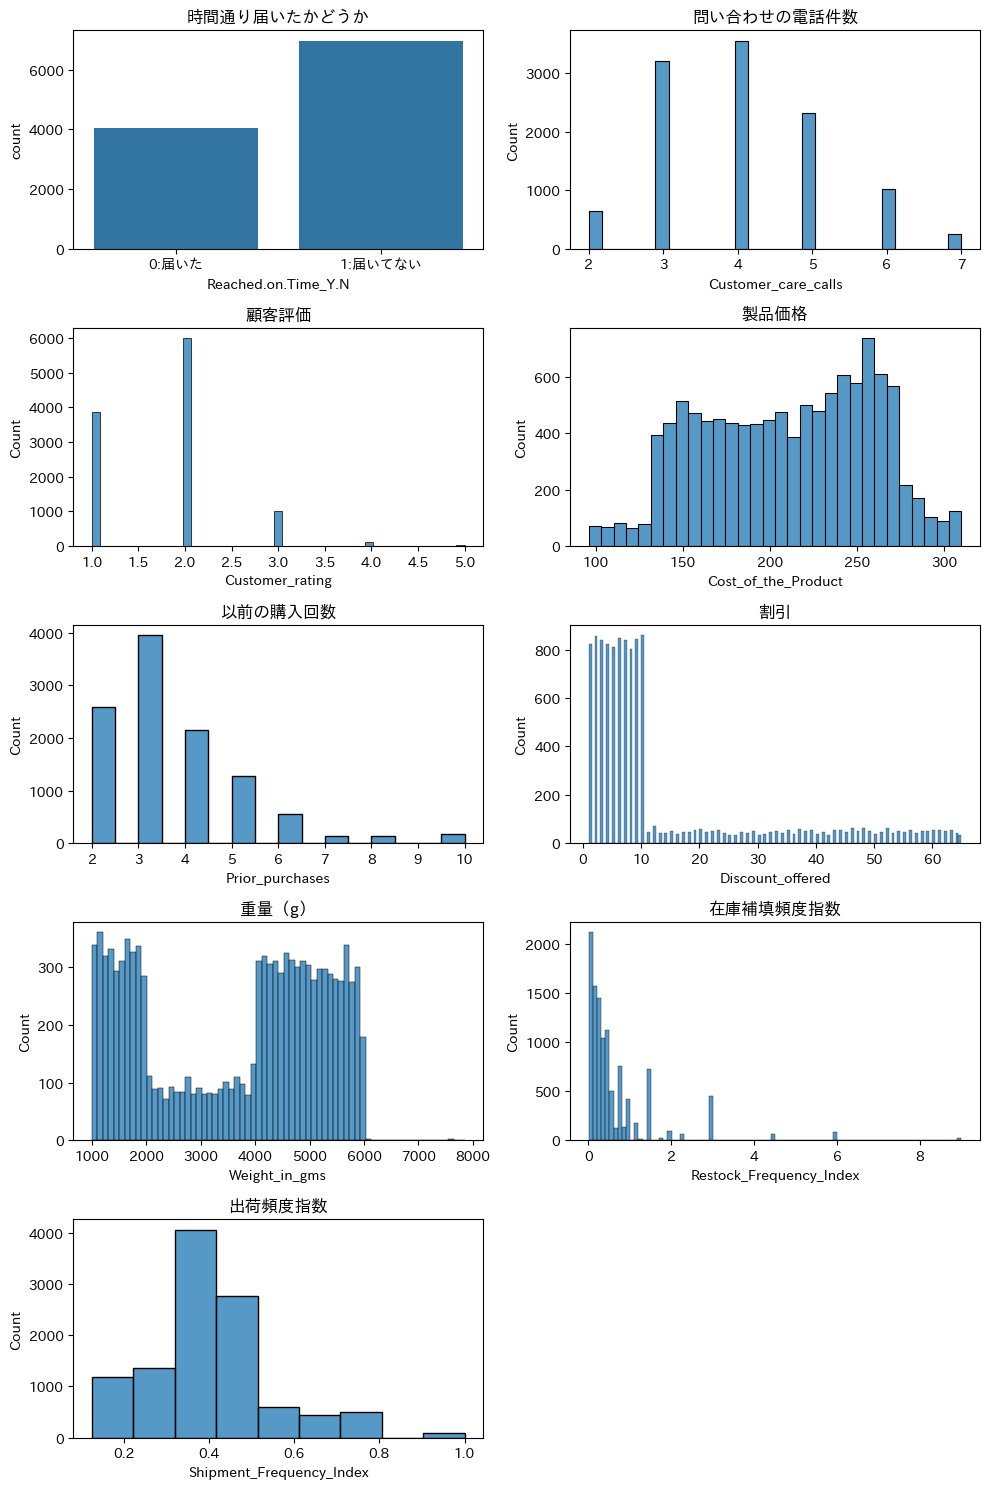

In [ ]:
# Plot configurations
fig, axes = plt.subplots(5, 2, figsize=(10, 15))

# 時間通り届いたかどうか（0:届いた、1:届いていない）
sns.countplot(data=df, x='Reached.on.Time_Y.N', ax=axes[0, 0])
axes[0, 0].set_title('時間通り届いたかどうか')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['0:届いた', '1:届いてない'])

# 問い合わせの電話件数
sns.histplot(df, x='Customer_care_calls', kde=False, ax=axes[0, 1])
axes[0, 1].set_title('問い合わせの電話件数')

# 顧客評価
sns.histplot(df, x='Customer_rating', kde=False, ax=axes[1, 0])
axes[1, 0].set_title('顧客評価')

# 製品価格
sns.histplot(df, x='Cost_of_the_Product', kde=False, ax=axes[1, 1])
axes[1, 1].set_title('製品価格')

# 以前の購入回数
sns.histplot(df, x='Prior_purchases', binwidth=0.5, kde=False, ax=axes[2, 0])
axes[2, 0].set_title('以前の購入回数')

# 割引
sns.histplot(df, x='Discount_offered', binwidth=0.5, kde=False, ax=axes[2, 1])
axes[2, 1].set_title('割引')

# 重さ
sns.histplot(df, x='Weight_in_gms', binwidth=100, kde=False, ax=axes[3, 0])
axes[3, 0].set_title('重量（g）')

# 在庫補填頻度
sns.histplot(df, x='Restock_Frequency_Index', binwidth=0.1, kde=False, ax=axes[3, 1])
axes[3, 1].set_title('在庫補填頻度指数')

# 出荷頻度
sns.histplot(df, x='Shipment_Frequency_Index', binwidth=0.1, kde=False, ax=axes[4, 0])
axes[4, 0].set_title('出荷頻度指数')

# 余った枠は非表示
axes[4, 1].axis('off')

plt.tight_layout()
plt.show()

数値系カラムの可視化により、製品価格は、100～130ドルの範囲の製品が比較的少なく、割引率は0～10％に集中し、重量は2000～4000gの範囲が比較的少ないことが分かります。

今回の分析で中心的に扱う配送遅延について、もう少し詳しく確認します。

In [ ]:
target_col = 'Reached.on.Time_Y.N'
delay_rate = df[target_col].mean()
print(f'配送遅延率: {delay_rate:.1%}')

df[target_col].value_counts(normalize=True)

配送遅延率: 63.3%


,proportion
Reached.on.Time_Y.N,
1,0.633058
0,0.366942


今回のデータでは、配送遅延率は **63.3%** でした。  
つまり、全体の半数を大きく超える注文が時間通りに届いていないことになります。

市場分析では、EC企業にとって配送遅延が重要な課題になりうることを確認しました。  
今回のデータでも配送遅延が高い割合で発生しているため、この企業においても配送遅延は深掘りする価値のある課題だと考えられます。

## 3-2. カテゴリカラムの分布を見る

倉庫、配送手段、商品の重要度などの分布を確認します。

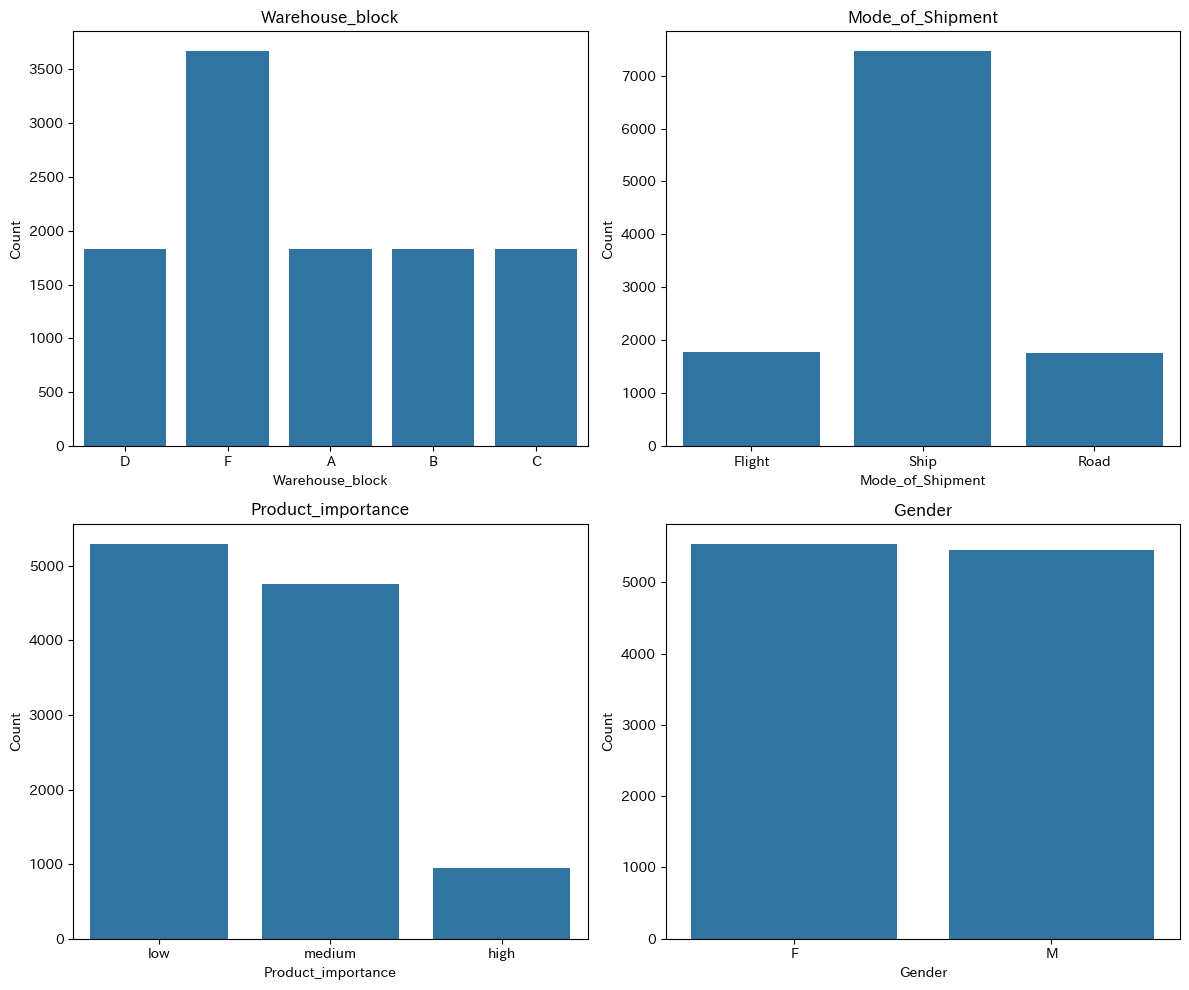

In [ ]:
obj_cols = df.select_dtypes(include='object').columns

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, col in enumerate(obj_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

for j in range(len(obj_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

倉庫はA～Dまではほぼ等しく、Fが他の倉庫の約2倍になっていること、輸送手段はShip(船)が多いこと、製品の重要度はlowとmediumが多く、highの割合は少ないことなどがわかります。

**ここまでのまとめ**
- データ数: 10999
- カラム数: 14
- 欠損値: 無し
- カテゴリカル変数: 4個
- 数値変数: 10個
- オンタイムに届いていない割合が約6割と高い、など


データ分析では、すべてのカラムを同じように見るのではなく、事業上特に重要そうな変数に注目することが大切です。  
例えば売上や利益のように、会社の意思決定に直結する変数があれば、それは重要な分析対象になります。

今回のデータには売上や利益を直接表すカラムはありません。  
一方で、`Reached.on.Time_Y.N` は配送遅延の有無を表すカラムであり、EC企業の顧客体験や物流改善に関わる重要な変数です。

3-1で確認した通り、今回のデータでは配送遅延率が **63.3%** でした。  
この結果を踏まえ、本Notebookでは `Reached.on.Time_Y.N` を目的変数として扱い、配送遅延が起きやすい条件を分析していきます。

他にも、`Customer_rating`（顧客評価）や `Customer_care_calls`（問い合わせの電話件数）も重要な変数です。  
ただし、今回は配送遅延を中心テーマとしているため、これらは配送遅延との関係を見る補助的な変数として扱います。

## 3-3. 数値変数の相関を見る

最後に、数値変数どうしの関係を相関係数で確認します。  
相関が強い変数があれば、後のモデル解釈や事業提案のヒントになります。

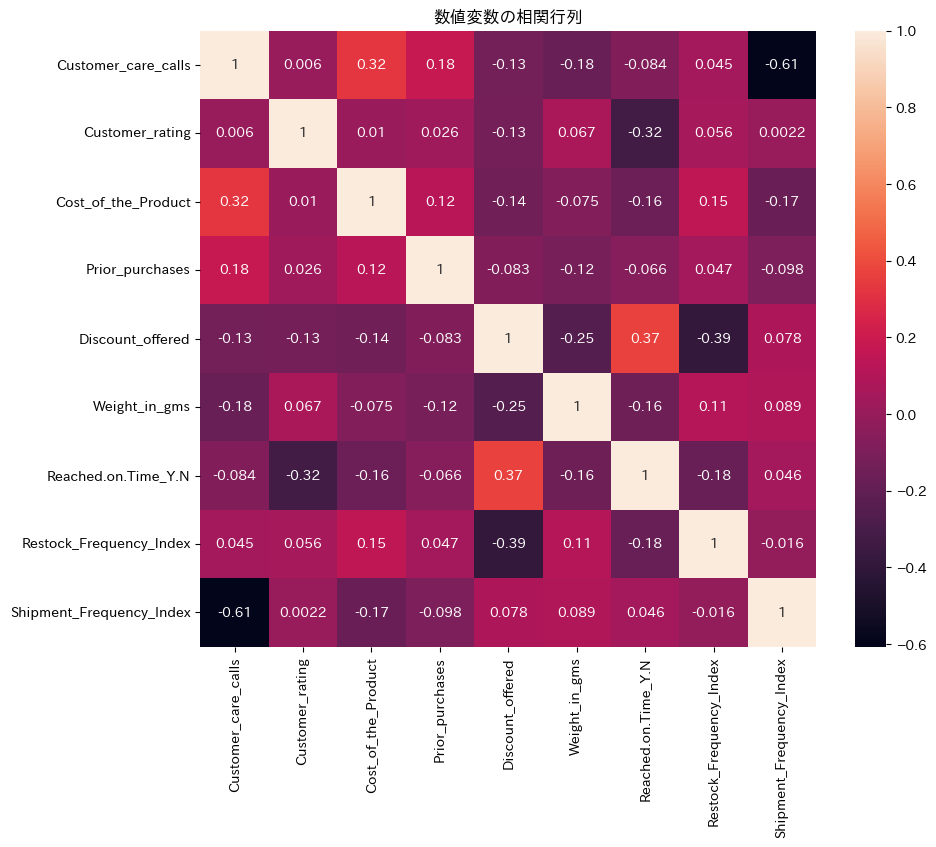

In [ ]:
# 数値データのみで相関行列を計算
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

# 相関行列のヒートマップを表示
sns.heatmap(corr, square=True, annot=True)
plt.title('数値変数の相関行列')
plt.show()

### 見るポイント

`Reached.on.Time_Y.N` と相関がある変数は、配送遅延と関係している可能性があります。  
ただし、相関は因果関係を意味しません。ここでは、後で詳しく見る変数を選ぶための手がかりとして使います。

以降では、配送遅延がどのような注文・商品・配送条件で起きやすいのかを確認していきます。

# 4. 配送遅延と関係しそうな要因を見る

ここでは、配送遅延と関係しそうな要因をいくつか確認します。  
初心者向けなので、複雑な統計検定は使わず、平均値やグラフで傾向を見ます。

## 4-1. 割引率と配送遅延

市場分析から、キャンペーンや割引による注文集中は配送負荷を高める可能性があります。  
そこで、割引率を **10%以下 / 11%以上** に二値化し、配送遅延との関係を見ます。

ここでは、単なる平均値ではなく、**件数の積み上げ棒グラフ**と**割合の積み上げ棒グラフ**を並べて確認します。

In [ ]:
# 'Discount_offered'を二値化（11%以上は1、10%以下は0）
df['Discount_offered_binary'] = (df['Discount_offered'] >= 11).astype(int)

df.groupby('Discount_offered_binary')[target_col].agg(['count', 'mean']).rename(
    columns={'count': '件数', 'mean': '遅延率'}
)

,件数,遅延率
Discount_offered_binary,,
0,8352,0.516762
1,2647,1.000000


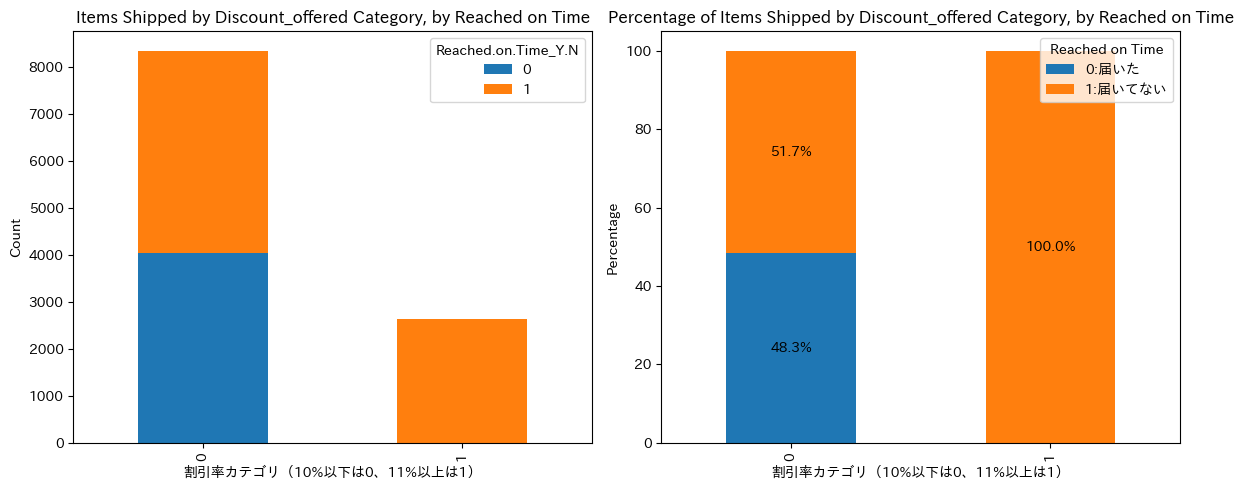

In [ ]:
# Plot configurations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ビンと'Reached.on.Time_Y.N'でグループ化してカウント
grouped = df.groupby(['Discount_offered_binary', target_col]).size().unstack()

# 積み上げ棒グラフを描画
grouped.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('割引率カテゴリ（10%以下は0、11%以上は1）')
axes[0].set_ylabel('Count')
axes[0].set_title('Items Shipped by Discount_offered Category, by Reached on Time')

# 各カテゴリの合計で正規化してパーセンテージを計算
grouped_pct = grouped.div(grouped.sum(axis=1), axis=0) * 100

# 積み上げバーグラフをプロット
ax = grouped_pct.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('割引率カテゴリ（10%以下は0、11%以上は1）')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Percentage of Items Shipped by Discount_offered Category, by Reached on Time')
axes[1].legend(title='Reached on Time', labels=['0:届いた', '1:届いてない'])

# バーの上にパーセンテージを表示
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 0:
        ax.text(x + width / 2,
                y + height / 2,
                f'{height:.1f}%',
                horizontalalignment='center',
                verticalalignment='center')

plt.tight_layout()
plt.show()

## 4-2. 重量と配送遅延

重量によって配送方法・倉庫オペレーション・出荷負荷が変わる可能性があります。  
重量を3カテゴリに分けて、配送遅延との関係を確認します。

In [ ]:
# 'Weight_in_gms'をカテゴライズ
df['Weight_category'] = pd.cut(
    df['Weight_in_gms'],
    bins=[0, 2000, 4000, float('inf')],
    labels=['Below 2000g', '2000g to 4000g', 'Above 4000g']
)

df.groupby('Weight_category', observed=False)[target_col].agg(['count', 'mean']).rename(
    columns={'count': '件数', 'mean': '遅延率'}
)

,件数,遅延率
Weight_category,,
Below 2000g,3245,0.672419
2000g to 4000g,1788,0.895414
Above 4000g,5966,0.533020


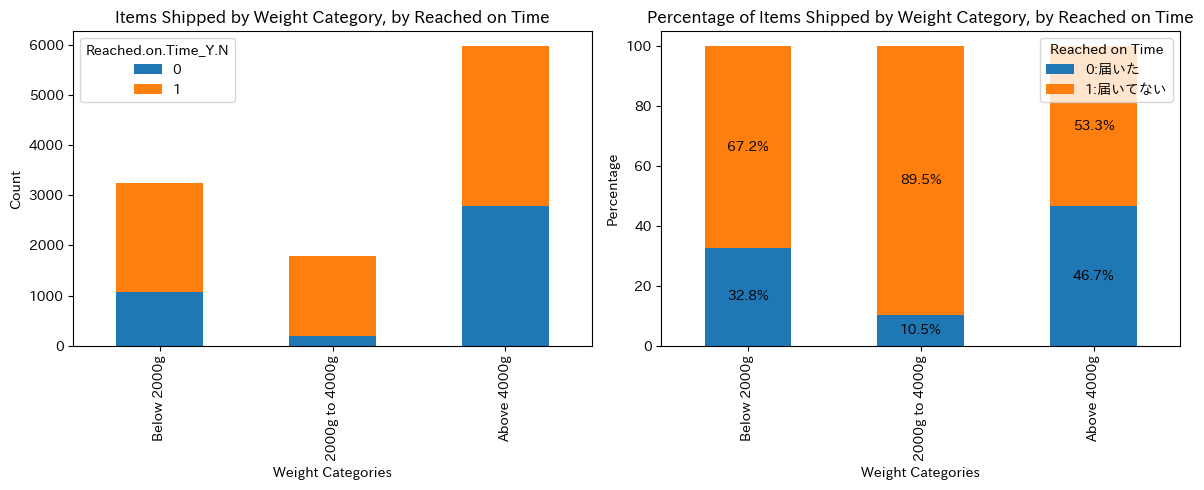

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

grouped = df.groupby(['Weight_category', target_col], observed=False).size().unstack()

# 件数の積み上げ棒グラフ
grouped.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('Weight Categories')
axes[0].set_ylabel('Count')
axes[0].set_title('Items Shipped by Weight Category, by Reached on Time')

# 割合の積み上げ棒グラフ
grouped_pct = grouped.div(grouped.sum(axis=1), axis=0) * 100
ax = grouped_pct.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('Weight Categories')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Percentage of Items Shipped by Weight Category, by Reached on Time')
axes[1].legend(title='Reached on Time', labels=['0:届いた', '1:届いてない'])

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 0:
        ax.text(x + width / 2,
                y + height / 2,
                f'{height:.1f}%',
                horizontalalignment='center',
                verticalalignment='center')

plt.tight_layout()
plt.show()

## 4-3. 配送手段と配送遅延

配送手段によって遅延率が異なるかを確認します。  
ここも、件数と割合を並べることで「母数の多さ」と「遅延率の高さ」を分けて見ます。

In [ ]:
shipment_delay = pd.crosstab(
    df['Mode_of_Shipment'],
    df[target_col],
    normalize='index'
)
shipment_delay

Reached.on.Time_Y.N,0,1
Mode_of_Shipment,,
Flight,0.360720,0.639280
Road,0.373295,0.626705
Ship,0.366926,0.633074


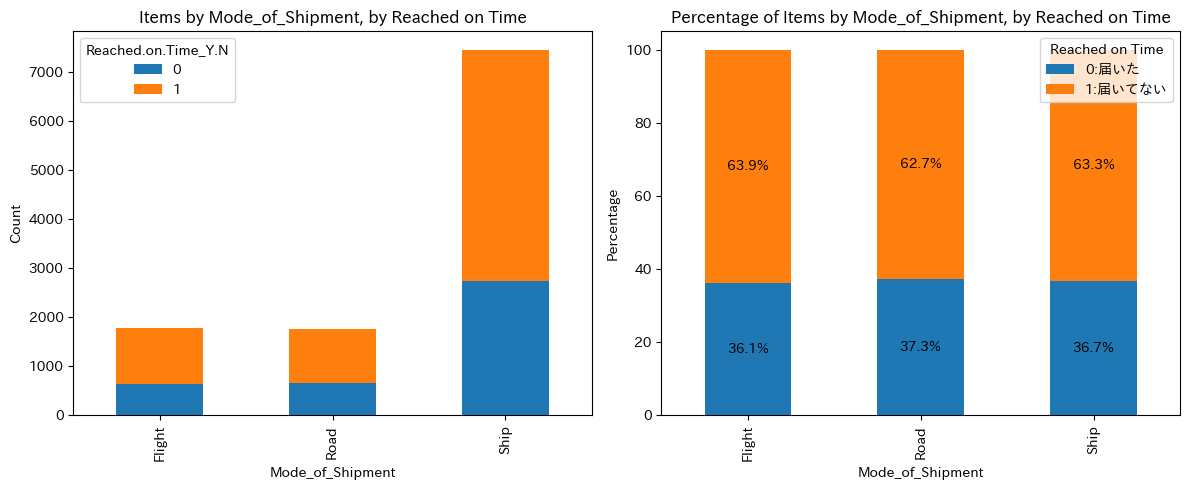

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

grouped = df.groupby(['Mode_of_Shipment', target_col]).size().unstack()
grouped.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('Mode_of_Shipment')
axes[0].set_ylabel('Count')
axes[0].set_title('Items by Mode_of_Shipment, by Reached on Time')

grouped_pct = grouped.div(grouped.sum(axis=1), axis=0) * 100
ax = grouped_pct.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('Mode_of_Shipment')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Percentage of Items by Mode_of_Shipment, by Reached on Time')
axes[1].legend(title='Reached on Time', labels=['0:届いた', '1:届いてない'])

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 0:
        ax.text(x + width / 2, y + height / 2, f'{height:.1f}%',
                ha='center', va='center')

plt.tight_layout()
plt.show()

## 4-4. 倉庫と配送遅延

倉庫ごとに遅延率が違う場合、オペレーション改善のヒントになります。  
件数と割合を並べてみましょう。

In [ ]:
warehouse_delay = pd.crosstab(
    df['Warehouse_block'],
    df[target_col],
    normalize='index'
)
warehouse_delay

Reached.on.Time_Y.N,0,1
Warehouse_block,,
A,0.371522,0.628478
B,0.365521,0.634479
C,0.366612,0.633388
D,0.370774,0.629226
F,0.363612,0.636388


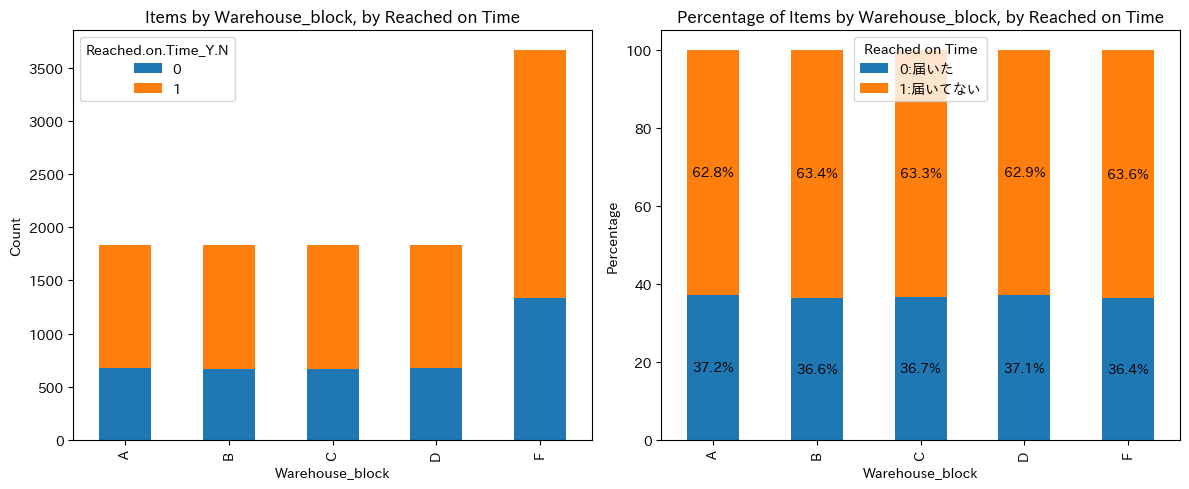

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

grouped = df.groupby(['Warehouse_block', target_col]).size().unstack()
grouped.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('Warehouse_block')
axes[0].set_ylabel('Count')
axes[0].set_title('Items by Warehouse_block, by Reached on Time')

grouped_pct = grouped.div(grouped.sum(axis=1), axis=0) * 100
ax = grouped_pct.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('Warehouse_block')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Percentage of Items by Warehouse_block, by Reached on Time')
axes[1].legend(title='Reached on Time', labels=['0:届いた', '1:届いてない'])

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 0:
        ax.text(x + width / 2, y + height / 2, f'{height:.1f}%',
                ha='center', va='center')

plt.tight_layout()
plt.show()

## 4-5. 需給関連カラムと配送遅延を見る

市場分析と業務フロー整理から、配送遅延は「配送方法」だけでなく、**在庫補填と出荷のバランス**にも関係しうると考えました。

そこで、`Restock_Frequency_Index`（在庫補填頻度）と `Shipment_Frequency_Index`（出荷頻度）から **需給指標** を作ります。

ここでは、以下のように定義します。

> 需給指標 = `Restock_Frequency_Index / Shipment_Frequency_Index` を `log1p` で変換した値

直感的には、値が小さいほど「出荷頻度に対して在庫補填が弱い」可能性がある、と解釈します。  
今回はこの需給指標が **0.5以下** の注文群・商品属性群を改善対象候補として見てみましょう。

※これは授業用の簡易指標です。実務では、実在庫、欠品率、リードタイム、発注単位、倉庫キャパシティ、実際の商品IDなども確認します。

In [ ]:
# 需給指標を計算して新しいカラムを作成
# Restock / Shipment を log1p で変換します。
df['需給指標'] = df['Restock_Frequency_Index'] / df['Shipment_Frequency_Index']
df['需給指標'] = np.log1p(df['需給指標'])

# 可視化用にビン分け
df['需給指標_binned'] = pd.cut(df['需給指標'], bins=25)

df[['Restock_Frequency_Index', 'Shipment_Frequency_Index', '需給指標', target_col]].head()

,Restock_Frequency_Index,Shipment_Frequency_Index,需給指標,Reached.on.Time_Y.N
0,0.034091,0.200000,0.157392,1
1,0.025424,0.200000,0.119665,1
2,0.062500,0.333333,0.171850,1
3,0.300000,0.250000,0.788457,1
4,0.065217,0.333333,0.178692,1


In [ ]:
df.groupby(target_col)[[
    'Restock_Frequency_Index',
    'Shipment_Frequency_Index',
    '需給指標'
]].mean()

,Restock_Frequency_Index,Shipment_Frequency_Index,需給指標
Reached.on.Time_Y.N,,,
0,0.879413,0.407292,1.020892
1,0.527668,0.422078,0.661511


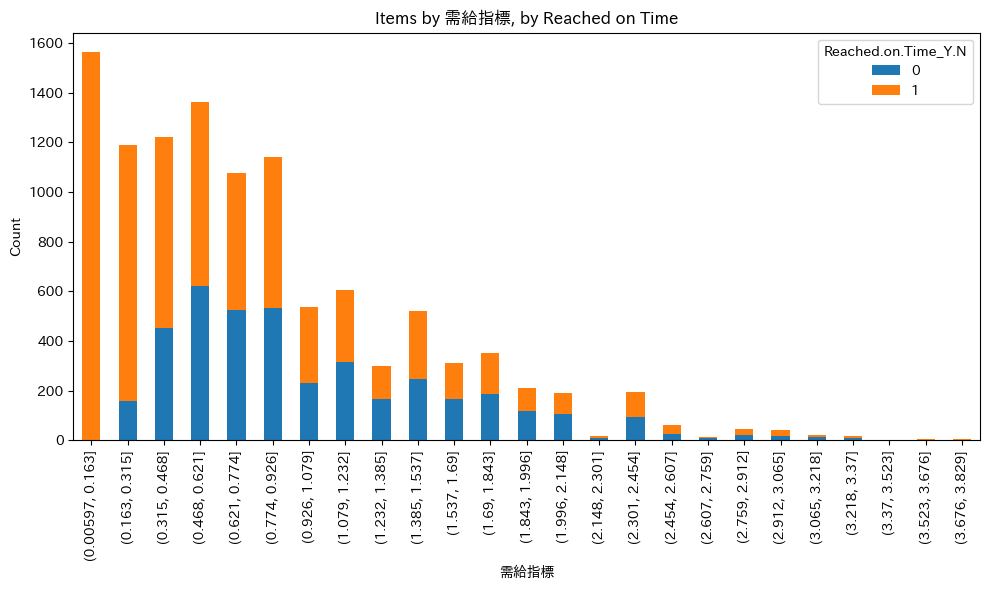

In [ ]:
# グループ化して積み上げ棒グラフを作成
fig, ax = plt.subplots(figsize=(10, 6))
grouped = df.groupby(['需給指標_binned', target_col], observed=False).size().unstack()
grouped.plot(kind='bar', stacked=True, ax=ax)
ax.set_xlabel('需給指標')
ax.set_ylabel('Count')
ax.set_title('Items by 需給指標, by Reached on Time')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 需給指標を注文群・商品属性群として見る

事業提案では、個別注文を1件ずつ見るだけでなく、**どの注文群・商品属性群を優先的に確認するか**を考える必要があります。

需給指標を **0.5以下 / 0.5より大きい** に分けて検証します。値が低いグループは、出荷頻度に対して在庫補填が弱い可能性があるため、改善対象候補として見ます。

ただし、このデータには実際の商品IDや在庫数は含まれていません。そのため、ここでいう「注文群・商品属性群」は、実務上の製品マスタに基づく分類ではなく、データ上の特徴量から作った分析上のグループです。

In [ ]:
# 0.5以上か0.5以下で分ける新しいカラムを作成
df['需給指標_bin'] = df['需給指標'].apply(lambda x: '0.5以上' if x >= 0.5 else '0.5以下')

supply_group_delay = df.groupby('需給指標_bin')[target_col].agg(['count', 'mean'])
supply_group_delay.rename(columns={'count': '件数', 'mean': '遅延率'})

,件数,遅延率
需給指標_bin,,
0.5以上,6634,0.509497
0.5以下,4365,0.820848


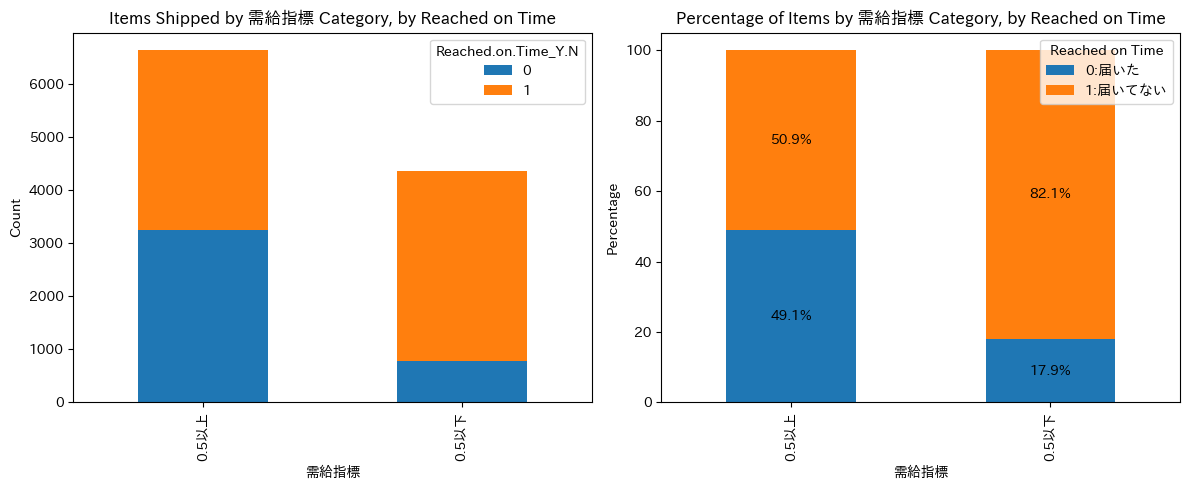

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

grouped = df.groupby(['需給指標_bin', target_col]).size().unstack()

# 件数の積み上げ棒グラフ
grouped.plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_xlabel('需給指標')
axes[0].set_ylabel('Count')
axes[0].set_title('Items Shipped by 需給指標 Category, by Reached on Time')

# 割合の積み上げ棒グラフ
grouped_pct = grouped.div(grouped.sum(axis=1), axis=0) * 100
ax = grouped_pct.plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('需給指標')
axes[1].set_ylabel('Percentage')
axes[1].set_title('Percentage of Items by 需給指標 Category, by Reached on Time')
axes[1].legend(title='Reached on Time', labels=['0:届いた', '1:届いてない'])

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 0:
        ax.text(x + width / 2, y + height / 2, f'{height:.1f}%',
                ha='center', va='center')

plt.tight_layout()
plt.show()

### ここから分かること

もし需給指標が低いグループで遅延率が高ければ、**配送遅延を減らすには、出荷頻度に対して在庫補填が弱い可能性のある注文群・商品属性群を優先して確認する**という問いにつながります。

つまり、今回の大きな問いである

> 配送遅延を減らすために、どの注文群・商品属性群の需給を優先的に確認すべきか？

は、**市場分析だけから出てきたものではなく、業務フローとEDAを踏まえて出てきた問い**として説明できます。

# 5. 課題仮説を立てる

市場分析では、EC市場の拡大や物流負荷の増加を背景に、配送遅延がEC企業にとって重要な課題になりうることを整理しました。

さらに、業務フローを考えると、配送遅延は配送会社だけの問題ではなく、**在庫補填・出荷頻度・注文集中・配送手段**の影響を受ける可能性があります。

そのうえでEDAを行い、今回のデータでも以下を確認しました。

- 配送遅延がどの程度発生しているか
- 割引率・重量・配送手段・倉庫によって遅延率に違いがありそうか
- 在庫補填頻度と出荷頻度から、需給負荷の高そうな注文群・商品属性群を作れるか

ここまでを踏まえると、次のような課題仮説を立てることができます。

## 課題仮説

このEC企業では、**市場全体の物流負荷増加を背景に、出荷頻度に対して在庫補填が弱い注文群・商品属性群や、注文が集中しやすい注文群・商品属性群で、配送遅延が起きやすい可能性がある**。

したがって、今回の分析では以下の問いに答えることを目指します。

> **配送遅延を減らすために、どの注文群・商品属性群の需給を優先的に確認すべきか？**

この問いは、ここまでの以下の分析から出てきています。

1. **市場分析**：配送遅延はEC企業にとって重要な課題候補である
2. **業務フロー**：遅延は在庫補填・出荷・配送の流れで発生しうる
3. **EDA**：今回のデータでも遅延率や各変数との関係を確認し、需給関連カラムにも着目する必要がある

次の章では、この課題仮説をさらに検討するために、配送遅延を目的変数としたモデルを作成します。モデルは、この時点で問いを生み出す根拠ではなく、**この問いに対して優先対象を絞るための後続分析**として位置づけます。

そのため、単に「遅延を予測するモデル」を作るのではなく、**遅延リスクが高く、かつ需給改善の対象になりうる注文群・商品属性群を見つける**ことを目的にします。

# 6. 機械学習モデルで配送遅延を予測する

ここでは、配送遅延を予測する簡単なモデルを作ります。  
高度な精度を目指すよりも、**モデルを事業提案にどうつなげるか**を理解することを重視します。

## 6-1. 使うカラムを選ぶ

今回は、配送前または配送時点で分かりそうな情報を中心に使います。  
`Customer_rating` は配送後に決まる情報の可能性があるため、モデルには入れません。

また、今回の問いが「どの注文群・商品属性群の需給を優先的に確認すべきか」なので、以下の需給関連カラムもモデルに入れます。

- `Restock_Frequency_Index`
- `Shipment_Frequency_Index`
- `需給指標`

加えて、`Discount_offered` も使用します。割引率は配送前に分かる情報であり、キャンペーンや需要集中の proxy になりうるためです。  
ただし、`Discount_offered` は目的変数と強く関係する可能性があるため、Feature Importanceを読むときは「割引が遅延の直接原因である」と決めつけないよう注意します。

これにより、モデル結果を単なる予測精度ではなく、**需給改善の優先順位づけ**につなげやすくします。

In [ ]:
use_cols = [
    'Warehouse_block',
    'Mode_of_Shipment',
    'Customer_care_calls',
    'Cost_of_the_Product',
    'Prior_purchases',
    'Product_importance',
    'Discount_offered',
    'Weight_in_gms',
    'Restock_Frequency_Index',
    'Shipment_Frequency_Index',
    '需給指標'
]

X = df[use_cols].copy()
y = df[target_col].copy()

X.head()

,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Cost_of_the_Product,Prior_purchases,Product_importance,Discount_offered,Weight_in_gms,Restock_Frequency_Index,Shipment_Frequency_Index,需給指標
0,D,Flight,4,177,3,low,44,5335,0.034091,0.200000,0.157392
1,F,Flight,4,216,2,low,59,2941,0.025424,0.200000,0.119665
2,A,Flight,2,183,4,low,48,3374,0.062500,0.333333,0.171850
3,B,Flight,3,176,4,medium,10,1149,0.300000,0.250000,0.788457
4,C,Flight,2,184,3,medium,46,2484,0.065217,0.333333,0.178692


## 6-2. カテゴリ変数を数値に変換する

機械学習モデルは文字列をそのまま扱えないため、カテゴリ変数をダミー変数に変換します。

In [ ]:
X = pd.get_dummies(X, drop_first=True)
X.head()

,Customer_care_calls,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Restock_Frequency_Index,Shipment_Frequency_Index,需給指標,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium
0,4,177,3,44,5335,0.034091,0.200000,0.157392,False,False,True,False,False,False,True,False
1,4,216,2,59,2941,0.025424,0.200000,0.119665,False,False,False,True,False,False,True,False
2,2,183,4,48,3374,0.062500,0.333333,0.171850,False,False,False,False,False,False,True,False
3,3,176,4,10,1149,0.300000,0.250000,0.788457,True,False,False,False,False,False,False,True
4,2,184,3,46,2484,0.065217,0.333333,0.178692,False,True,False,False,False,False,False,True


## 6-3. 学習データとテストデータに分ける

モデルを作るためのデータと、モデルの性能を確認するためのデータに分けます。

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('学習データ:', X_train.shape)
print('テストデータ:', X_test.shape)

学習データ: (8799, 16)
テストデータ: (2200, 16)


## 6-4. モデルを学習する

今回は、扱いやすい `RandomForestClassifier` を使います。

In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, random_state=42)

## 6-5. モデルを評価する

作成したモデルの評価指標として、２値分類であることと、真陽性率（True Positive Rate）と偽陽性率（False Positive Rate）のバランスを取って評価し、モデルの精度を汎用的に計測することができるAUCを用いることにします。

In [ ]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print('Accuracy:', accuracy_score(y_test, y_pred))
print('AUC:', roc_auc_score(y_test, y_pred_proba))
print('Classification report')
print(classification_report(y_test, y_pred))

Accuracy: 0.655
AUC: 0.7392254243424593
Classification report
              precision    recall  f1-score   support

           0       0.53      0.59      0.56       807
           1       0.75      0.69      0.72      1393

    accuracy                           0.66      2200
   macro avg       0.64      0.64      0.64      2200
weighted avg       0.67      0.66      0.66      2200



In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=['Actual on time', 'Actual delayed'],
    columns=['Predicted on time', 'Predicted delayed']
)
cm_df

,Predicted on time,Predicted delayed
Actual on time,478,329
Actual delayed,430,963


### 評価結果の見方

この段階では、モデル精度が完璧である必要はありません。  
重要なのは、モデルが配送遅延リスクの高い注文をある程度見分けられるか、そして事業施策に使えるヒントが得られるかです。

# 7. モデルの結果を解釈する

モデルがどの変数を重視しているかを見ることで、配送遅延に関係しそうな要因を確認します。

ここで特に確認したいのは、`Restock_Frequency_Index`、`Shipment_Frequency_Index`、`需給指標` などの需給関連変数が、配送遅延予測にどの程度使われているかです。

もし需給関連変数の重要度が高ければ、**需給改善を優先する事業提案**につなげやすくなります。

In [ ]:
importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

importance.head(15)

,feature,importance
3,Discount_offered,0.330066
5,Restock_Frequency_Index,0.318704
7,需給指標,0.170108
4,Weight_in_gms,0.082287
1,Cost_of_the_Product,0.049565
14,Product_importance_low,0.015132
2,Prior_purchases,0.014014
0,Customer_care_calls,0.007880
6,Shipment_Frequency_Index,0.004669
15,Product_importance_medium,0.004342


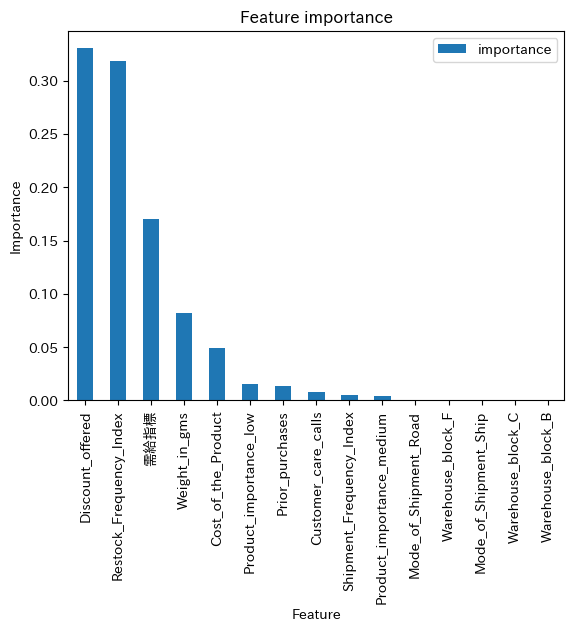

In [ ]:
importance.head(15).plot(x='feature', y='importance', kind='bar')
plt.title('Feature importance')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.show()

### 考えること

重要度が高い変数は、配送遅延と関係している可能性があります。  
ただし、重要度が高いからといって、必ずその変数が遅延の原因であるとは限りません。  

ここでは、事業提案の「仮説」を作る材料として使います。

# 8. 遅延リスクが高い注文を確認する

モデルを使うと、各注文について「遅延しそうな確率」を出すことができます。  
この確率が高い注文を、事前対応の対象にするという施策を考えます。

In [ ]:
result = X_test.copy()
result['delay_probability'] = y_pred_proba
result['actual_delay'] = y_test.values

result.sort_values('delay_probability', ascending=False).head(10)

,Customer_care_calls,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Restock_Frequency_Index,Shipment_Frequency_Index,需給指標,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_low,Product_importance_medium,delay_probability,actual_delay
1135,6,257,3,60,2266,0.050000,0.285714,0.161268,False,False,False,True,False,True,False,True,0.999892,1
1630,6,286,7,65,3362,0.046154,0.428571,0.102279,False,True,False,False,True,False,False,True,0.999437,1
114,3,168,2,50,1616,0.090000,0.750000,0.113329,False,False,True,False,True,False,False,False,0.999303,1
822,3,268,3,33,2000,0.045455,0.250000,0.167054,False,False,True,False,False,False,True,False,0.999251,1
115,3,176,3,36,3021,0.125000,0.750000,0.154151,False,False,False,True,True,False,False,False,0.999247,1
1855,5,247,10,61,2206,0.049180,0.333333,0.137621,False,False,False,True,False,True,False,True,0.999195,1
2787,5,264,10,34,2960,0.088235,0.333333,0.234840,True,False,False,False,False,True,False,True,0.999195,1
309,5,266,3,53,3089,0.056604,0.333333,0.156842,True,False,False,False,False,True,False,True,0.999188,1
2607,3,218,3,52,3142,0.057692,0.250000,0.207639,True,False,False,False,False,False,False,True,0.999188,1
2401,5,259,3,43,2685,0.069767,0.333333,0.190044,False,False,False,True,False,True,False,True,0.999188,1


In [ ]:
high_risk = result[result['delay_probability'] >= 0.7]

print('高リスク注文数:', len(high_risk))
print('高リスク注文の実際の遅延率:', high_risk['actual_delay'].mean())
high_risk.describe()

高リスク注文数: 591
高リスク注文の実際の遅延率: 1.0


,Customer_care_calls,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Restock_Frequency_Index,Shipment_Frequency_Index,需給指標,delay_probability,actual_delay
count,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.000000,591.0
mean,3.800338,190.890017,3.350254,33.898477,2840.172589,0.095136,0.434087,0.214683,0.973314,1.0
std,1.022161,45.786236,1.564705,18.429523,1409.155053,0.079349,0.164438,0.180646,0.049119,0.0
min,2.000000,96.000000,2.000000,4.000000,1008.000000,0.009677,0.142857,0.013245,0.703228,1.0
25%,3.000000,155.000000,2.000000,17.000000,1636.000000,0.045455,0.333333,0.093332,0.965832,1.0
50%,4.000000,182.000000,3.000000,34.000000,2598.000000,0.070588,0.400000,0.162519,0.994490,1.0
75%,5.000000,230.000000,4.000000,51.000000,3803.000000,0.125000,0.500000,0.287682,0.997869,1.0
max,7.000000,296.000000,10.000000,65.000000,7588.000000,0.500000,1.000000,1.386294,0.999892,1.0


### 考えること

高リスク注文の実際の遅延率が全体平均より高ければ、モデルを使って注意すべき注文をある程度絞り込めていると考えられます。

# 9. 事業提案を作る

最後に、市場分析、EDA、モデル結果をつなげて、事業提案にまとめます。

## 提案の方向性

市場分析から、EC市場の拡大や物流負荷の増加により、配送遅延はEC企業にとって重要な課題になりうることが分かりました。

業務フローを見ると、配送遅延は配送だけでなく、在庫補填と出荷頻度のバランスにも関係する可能性があります。

さらに今回のデータでも、配送遅延が一定程度発生しており、EDAとRandomForestモデルの結果から、割引率、重量、配送手段、倉庫、需給関連指標が配送遅延と関係している可能性が示唆されました。

したがって、今回の事業提案の中心は次の問いになります。

> **配送遅延を減らすために、どの注文群・商品属性群の需給を優先的に確認すべきか？**

## 施策1：需給指標が低い注文群・商品属性群を優先管理する

`需給指標` が低い注文群・商品属性群は、出荷頻度に対して在庫補填が弱い可能性があります。  
このグループを優先的に確認し、在庫補填頻度の見直しや出荷計画の調整を検討します。

## 施策2：高リスク注文の事前検知

MLモデルで配送遅延リスクが高い注文を事前に抽出します。  
リスクが高い注文は、出荷前に在庫・配送手段・倉庫状況を確認します。

## 施策3：キャンペーン時の出荷体制強化

割引率が高い商品で遅延リスクが高い場合、キャンペーン前に出荷体制を強化します。  
具体的には、対象商品の在庫確認、出荷人員の追加、配送手段の見直しを行います。

## 施策4：需給・配送遅延ダッシュボード

倉庫別、配送手段別、商品重量別、需給指標別に遅延リスクを可視化します。  
現場担当者が、どの注文群・商品属性群・倉庫・配送手段で遅延リスクが高まっているかを早めに把握できるようにします。

このように、Biz提案では、**市場背景 → 業務フロー → EDA → モデルによる予測 → 優先対象候補 → 具体的な打ち手** が一本の線でつながっていることが重要です。

なお、このNotebookでは施策実施後の遅延件数削減効果までは試算していません。そのため、ここでの提案は「効果が確定した施策」ではなく、**次に検証すべき施策候補**として位置づけます。

# 10. ビジネス提案として伝わるかを確認する

最後に、この分析がビジネス提案として伝わる形になっているかを確認します。

分析量が多くても、以下のようになっていると、Biz提案としては伝わりにくくなります。

## 1. 市場分析が一般論で終わっている

悪い例：

> EC市場は拡大しています。物流業界では2024年問題があります。したがってAIを導入すべきです。

改善例：

> EC市場拡大と物流負荷の増加により、配送遅延はEC企業にとって重要な課題になりうる。今回のデータでも配送遅延率が高く、顧客評価との関係も示唆されたため、本分析では配送遅延改善を主要課題として設定する。

## 2. EDAがグラフを貼っただけになっている

悪い例：

> 割引率別、重量別、倉庫別にグラフを作成しました。

改善例：

> 割引率11%以上の注文群で遅延率が高い傾向が見られた。ただし、割引率そのものが原因とは限らないため、需要増や在庫補填不足の可能性を考え、次に在庫補填頻度と出荷頻度に着目した。

## 3. モデルの説明が精度報告で終わっている

悪い例：

> モデルを作成し、精度は〇〇でした。

改善例：

> 配送遅延を目的変数としてRandomForestモデルを構築した。ROC-AUCは〇〇でした。このモデルにより、配送遅延リスクの高い注文を抽出し、需給指標や割引率、重量、配送手段などを用いて、優先的に確認すべき注文群・商品属性群を整理した。

## 4. 打ち手が抽象的すぎる

悪い例：

> AIを用いて配送遅延を改善します。

改善例：

> AIを用いて需給指標が低く、モデル上の遅延リスクも高い注文群・商品属性群を優先対象を抽出し、在庫補填頻度の見直し、出荷計画の調整、配送手段の確認を行う。

## 5. 効果が「良くなりそう」で終わっている

悪い例：

> この施策により、配送遅延が改善し、顧客満足度が向上すると考えられます。

改善例：

> まずはモデルが高リスクと判定した注文群について、実際の遅延率や現場対応可能性を確認する。次のステップでは、対象注文数、対応コスト、遅延削減件数を比較し、PoCとして実施する優先順位を決める。

ビジネス提案として伝わる分析とは、分析量が多い資料ではありません。

- なぜその問題を扱うのか
- データから何が分かったのか
- その結果、どの打ち手候補を選ぶのか
- 次に何を検証すべきか

が一本の線でつながっている分析です。

# 11. 最終まとめ

このNotebookでは、EC配送データを使って、以下の流れを体験しました。

1. 市場分析から、配送遅延がEC企業にとって重要な課題候補であることを整理する  
2. 業務フローから、配送遅延が在庫補填・出荷・配送と関係しうることを考える  
3. EDAで、配送遅延の発生状況と関連しそうな変数を見る  
4. 在庫補填頻度と出荷頻度から、簡易的な需給指標を作る  
5. RandomForestモデルで配送遅延を予測する  
6. モデル結果をもとに、どの注文群・商品属性群の需給を優先的に確認すべきかを考える  
7. 事業提案として整理する  

重要なのは、**機械学習モデルを作ること自体ではなく、モデルを使ってどのような意思決定や施策候補につなげるか**です。

今回の大きな問いである

> 配送遅延を減らすために、どの注文群・商品属性群の需給を優先的に確認すべきか？

は、いきなり置かれた問いではなく、**市場分析・業務フロー・EDAから導かれた問い**として説明できます。

なお、このNotebookでは施策効果の厳密なシミュレーションまでは行っていません。到達点は、配送遅延リスクが高く、需給面から確認すべき対象を抽出し、次のPoCや現場確認につなげることです。

## 発展課題

時間があれば、以下にも取り組んでみてください。

- 遅延リスクの閾値を変えると、対象注文数はどう変わるか
- 需給指標の定義を変えると、結果はどう変わるか
- 他のモデルを使うと精度は上がるか
- 顧客評価と配送遅延の関係を見る
- 倉庫別に改善施策を考える
- キャンペーン時の配送負荷を想定した施策を考える
- 施策を実施した場合の対象件数・対応コスト・遅延削減見込みを試算する

謝辞：以下データセット利用に関して

引用元：Gopalani, P. (prachi13). Customer Analytics (E-Commerce Shipping Data).

https://www.kaggle.com/datasets/prachi13/customer-analytics